# 🩺 Détection du cancer du sein
**UMEF AI Bootcamp** · GalsenAI Ambassador Program · Swiss UMEF University

| | |
|---|---|
| **Type de problème** | Classification (prédire une catégorie : tumeur maligne ou bénigne) |
| **Variable à prédire** | la tumeur est-elle maligne (1) ou bénigne (0) ? |
| **Niveau** | ⭐ Facile (données propres) |
| **Durée conseillée** | environ 2 h en équipe |

## Comment utiliser ce notebook
1. Ouvre-le dans **Google Colab** (colab.research.google.com → Fichier → Importer).
2. Lance les cellules **dans l'ordre** (touches `Maj + Entrée`). Quand une cellule demande le fichier de données, choisis `Breast_cancer.csv`.
3. Lis les textes entre les cellules : ils expliquent **pourquoi** on fait chaque étape.
4. Les questions 🤔 sont pour ton équipe : discutez-en avant de passer à la suite.

### ✏️ Version « à compléter »
- **Quelques cellules marquées ✏️ À TOI** sont à compléter (elles contiennent `...`). Chaque cellule a un indice, et un bloc « 💡 Je bloque » avec la solution : essaie d'abord, ouvre-le ensuite.

## Contexte
Après un prélèvement, on mesure des caractéristiques des cellules observées au microscope : taille, forme, texture… Peut-on, à partir de ces mesures, **prédire si une tumeur est maligne ou bénigne** ?

> ⚠️ **Exercice pédagogique.** Ce notebook illustre une technique d'apprentissage automatique. Il **ne remplace en aucun cas un diagnostic médical** : seul un professionnel de santé peut poser un diagnostic.

## Les données
569 cas du jeu de données classique *Wisconsin Diagnostic Breast Cancer* (aussi disponible dans scikit-learn). Chaque cas est décrit par 30 mesures calculées sur les cellules : pour 10 caractéristiques (rayon, texture, périmètre, aire, lissage, compacité, concavité, points concaves, symétrie, dimension fractale), on a la **moyenne**, l'**erreur** (variation) et la **pire valeur**.

## Ce que tu vas apprendre
- la **classification** binaire (deux catégories) ;
- pourquoi **le type d'erreur compte** : rater une tumeur maligne n'a pas le même coût que d'alerter à tort ;
- lire une **matrice de confusion**, la précision et le rappel ;
- utiliser des variables **très corrélées** entre elles.

## 1. Préparation de l'environnement

In [13]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, GridSearchCV, KFold, StratifiedKFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RANDOM_STATE = 42   # pour que tout le monde obtienne les mêmes résultats

## 2. Charger et regarder les données
On commence toujours par **regarder** : combien de lignes ? quelles colonnes ? quels types ? des valeurs manquantes ? des doublons ?

In [14]:
FICHIER = "Breast_cancer.csv"

# Si le fichier n'est pas encore dans Colab, on te demande de l'envoyer depuis ton ordinateur.
if not os.path.exists(FICHIER):
    try:
        from google.colab import files
        print(f"Choisis le fichier {FICHIER} sur ton ordinateur :")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Place le fichier {FICHIER} dans le même dossier que ce notebook.")

df = pd.read_csv(FICHIER)
print("Dimensions :", df.shape, "→", df.shape[0], "lignes et", df.shape[1], "colonnes")
df.head()

Dimensions : (569, 31) → 569 lignes et 31 colonnes


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,CLASS
0,17.990,10.380,122.800,"1,001.000",0.118,0.278,0.300,0.147,0.242,0.079,1.095,0.905,8.589,153.400,0.006,0.049,0.054,0.016,0.030,0.006,25.380,17.330,184.600,"2,019.000",0.162,0.666,0.712,0.265,0.460,0.119,0
1,20.570,17.770,132.900,"1,326.000",0.085,0.079,0.087,0.070,0.181,0.057,0.543,0.734,3.398,74.080,0.005,0.013,0.019,0.013,0.014,0.004,24.990,23.410,158.800,"1,956.000",0.124,0.187,0.242,0.186,0.275,0.089,0
2,19.690,21.250,130.000,"1,203.000",0.110,0.160,0.197,0.128,0.207,0.060,0.746,0.787,4.585,94.030,0.006,0.040,0.038,0.021,0.022,0.005,23.570,25.530,152.500,"1,709.000",0.144,0.424,0.450,0.243,0.361,0.088,0
3,11.420,20.380,77.580,386.100,0.142,0.284,0.241,0.105,0.260,0.097,0.496,1.156,3.445,27.230,0.009,0.075,0.057,0.019,0.060,0.009,14.910,26.500,98.870,567.700,0.210,0.866,0.687,0.258,0.664,0.173,0
4,20.290,14.340,135.100,"1,297.000",0.100,0.133,0.198,0.104,0.181,0.059,0.757,0.781,5.438,94.440,0.011,0.025,0.057,0.019,0.018,0.005,22.540,16.670,152.200,"1,575.000",0.137,0.205,0.400,0.163,0.236,0.077,0


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.isna().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
CLASS                      0
dtype: int64

In [18]:
# ✏️ À TOI (1/5) : compte les doublons et les valeurs manquantes
# Indice : df.duplicated() repère les lignes copiées, df.isna() repère les cases vides, et .sum() compte.
nb_doublons = df.duplicated().sum()
print("Lignes en double :", nb_doublons)
print("Valeurs manquantes par colonne :")
manquantes = df.isna().sum()
print(manquantes[manquantes > 0] if manquantes.sum() > 0 else "Aucune valeur manquante (mais attention aux valeurs bizarres, voir plus bas !)")
df.describe(include="all").T

Lignes en double : 0
Valeurs manquantes par colonne :
Aucune valeur manquante (mais attention aux valeurs bizarres, voir plus bas !)


,count,mean,std,min,25%,50%,75%,max
mean radius,569.000,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.000,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.000,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.000,654.889,351.914,143.500,420.300,551.100,782.700,"2,501.000"
mean smoothness,569.000,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.000,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.000,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.000,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.000,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.000,0.063,0.007,0.050,0.058,0.062,0.066,0.097


<details><summary>💡 Je bloque : voir la solution (1/5)</summary>

```python
nb_doublons = df.duplicated().sum()
manquantes = df.isna().sum()
```
</details>

🤔 **Questions pour l'équipe**
- Combien de cas y a-t-il ? Combien de colonnes ?
- Que contient la colonne `CLASS` ? (Indice : dans ce jeu de données, **0 = tumeur maligne** et **1 = tumeur bénigne**.)
- Y a-t-il des valeurs manquantes ou des doublons ?

## 3. Nettoyer les données
Les données sont déjà propres. Un seul changement, **très important** : dans le fichier, `CLASS = 0` veut dire **maligne** et `CLASS = 1` **bénigne**, ce qui est contre-intuitif. Nous créons une colonne `maligne` où **1 = maligne** : ce sera notre « classe positive », celle qu'on cherche à détecter.

In [19]:
# ✏️ À TOI (2/5) : supprime les lignes en double. Indice : méthode drop_duplicates()
avant = len(df)
df = df.drop_duplicates()
print(f"Doublons supprimés : {avant - len(df)}")

Doublons supprimés : 0


<details><summary>💡 Je bloque : voir la solution (2/5)</summary>

```python
df = df.drop_duplicates()
```
</details>

In [20]:
print("Répartition d'origine de CLASS (0 = maligne, 1 = bénigne) :")
if "CLASS" not in df.columns:
    df = pd.read_csv(FICHIER)

print(df["CLASS"].value_counts())

# ✏️ À TOI (3/5) : crée la colonne "maligne" : 1 si "CLASS" vaut 0, 0 sinon.
# Indice : (comparaison).astype(int)   -- 1 = tumeur maligne : c'est ce qu'on veut détecter
df["maligne"] = (df["CLASS"] == 0).astype(int)
df = df.drop(columns=["CLASS"])
df[["mean radius", "mean area", "maligne"]].head()

Répartition d'origine de CLASS (0 = maligne, 1 = bénigne) :
CLASS
1    357
0    212
Name: count, dtype: int64


,mean radius,mean area,maligne
0,17.990,"1,001.000",1
1,20.570,"1,326.000",1
2,19.690,"1,203.000",1
3,11.420,386.100,1
4,20.290,"1,297.000",1


<details><summary>💡 Je bloque : voir la solution (3/5)</summary>

```python
df["maligne"] = (df["CLASS"] == 0).astype(int)
```
</details>

In [21]:
TARGET = "maligne"
NOMS_CLASSES = ['Bénigne', 'Maligne']   # 0 → Bénigne ; 1 → Maligne
EQUILIBRER = False
print("Dimensions après nettoyage :", df.shape)

Dimensions après nettoyage : (569, 31)


## 4. Explorer les données (EDA)
L'**analyse exploratoire** sert à comprendre les données avant de modéliser : formes des distributions, liens entre variables, valeurs étranges.

🤔 *Après chaque graphique, notez ce que vous observez.*

In [22]:
def colonnes_par_type(data, cible):
    """Sépare les colonnes numériques et catégorielles (sans la cible)."""
    num = [c for c in data.select_dtypes(include="number").columns if c != cible]
    cat = [c for c in data.select_dtypes(exclude="number").columns if c != cible]
    return num, cat

num_cols, cat_cols = colonnes_par_type(df, TARGET)
print("Variables numériques  :", len(num_cols), num_cols[:8], "..." if len(num_cols) > 8 else "")
print("Variables catégorielles :", len(cat_cols), cat_cols)

Variables numériques  : 30 ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points'] ...
Variables catégorielles : 0 []


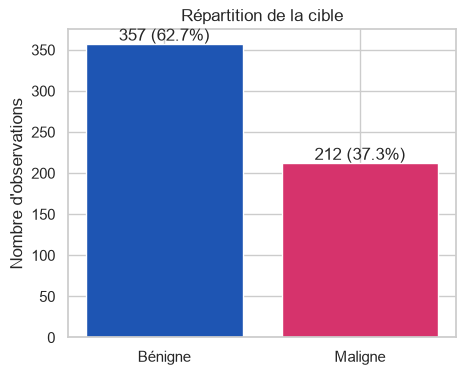

In [23]:
effectifs = df[TARGET].value_counts().sort_index()
pourcents = (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(1)
etiquettes = [NOMS_CLASSES[i] for i in effectifs.index]
plt.figure(figsize=(5, 4))
plt.bar(etiquettes, effectifs.values, color=["#1E55B3", "#D6336C"])
for i, (n, p) in enumerate(zip(effectifs.values, pourcents.values)):
    plt.text(i, n, f"{n} ({p}%)", ha="center", va="bottom")
plt.title("Répartition de la cible"); plt.ylabel("Nombre d'observations"); plt.show()

In [24]:
#on constate que la tumeur maligne est moins représentée que la tumeur bénigne, ce qui peut poser problème pour l'apprentissage du modèle.on constate aussi que tumeur benigne est plus elevée que tumeur maligne .

(On n'affiche que les 12 premières variables numériques sur 30.)


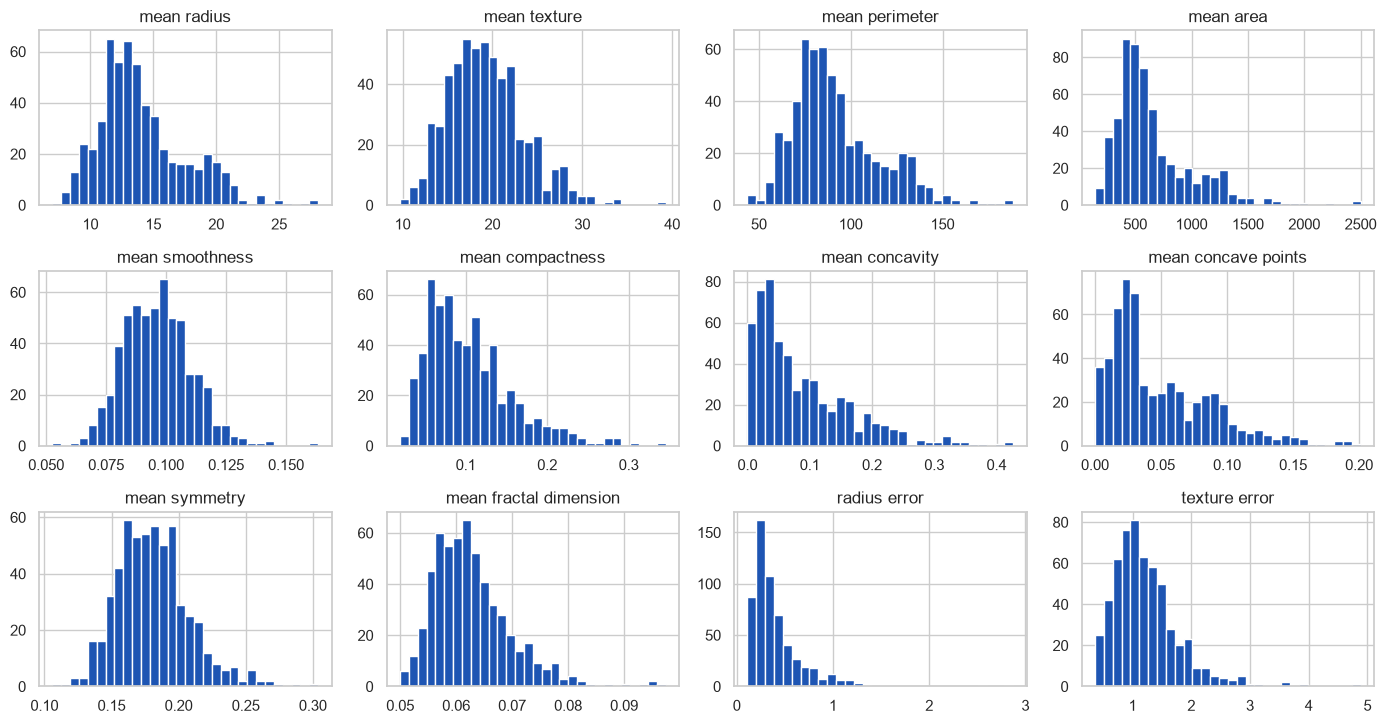

In [25]:
a_tracer = num_cols[:12]
if len(num_cols) > 12:
    print(f"(On n'affiche que les 12 premières variables numériques sur {len(num_cols)}.)")
df[a_tracer].hist(bins=30, figsize=(14, 3 + 2.2 * ((len(a_tracer) - 1) // 4)), color="#1E55B3", layout=(-1, 4))
plt.tight_layout(); plt.show()

In [26]:
# on constate que certaines variables ont des valeurs aberrantes (outliers) qui peuvent fausser l'apprentissage du modèle. Il faudra donc envisager de les traiter (par exemple en les supprimant ou en les transformant) avant de construire le modèle.

In [27]:
a_tracer = cat_cols[:6]
if a_tracer:
    n = len(a_tracer)
    fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(13, 3.6 * ((n + 1) // 2)))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, a_tracer):
        ordre = df[col].value_counts().head(10).index
        sns.countplot(y=df[col], order=ordre, ax=ax, color="#1E55B3")
        ax.set_title(col)
    for ax in axes[len(a_tracer):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Pas de variable catégorielle dans ce jeu de données.")

Pas de variable catégorielle dans ce jeu de données.


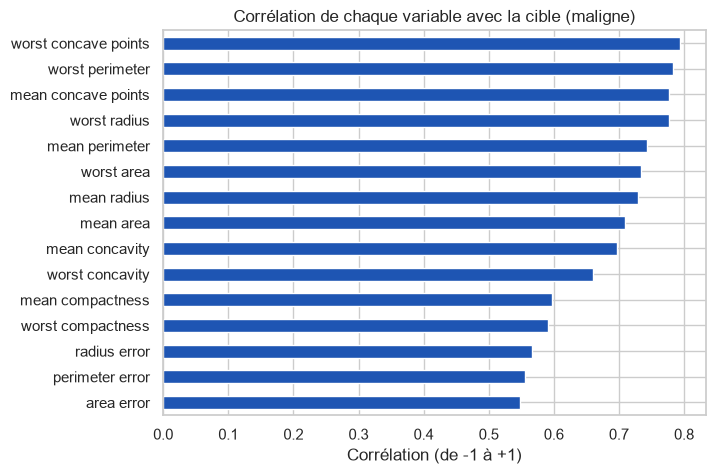

In [28]:
corr_cible = df[num_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
plt.figure(figsize=(7, 5))
corr_cible.head(15)[::-1].plot(kind="barh", color="#1E55B3")
plt.title(f"Corrélation de chaque variable avec la cible ({TARGET})")
plt.xlabel("Corrélation (de -1 à +1)"); plt.show()

if len(num_cols) <= 12:
    plt.figure(figsize=(9, 7))
    sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Matrice de corrélation"); plt.show()

In [29]:
#  on constate que certaines variables sont fortement corrélées entre elles, ce qui peut poser problème pour certains modèles (comme la régression logistique). Il faudra donc envisager de réduire la dimensionnalité (par exemple avec PCA) ou de supprimer certaines variables avant de construire le modèle.

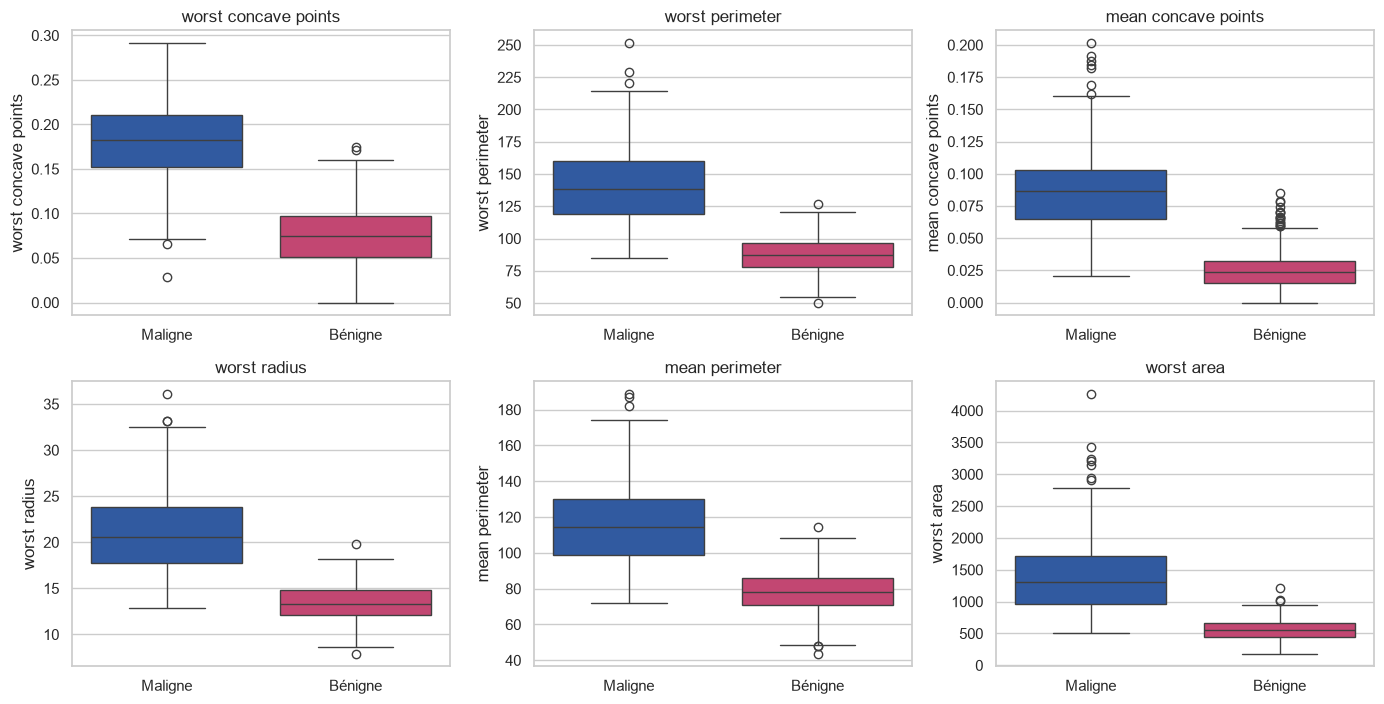

In [30]:
# Variables numériques : comparer les deux groupes
top_num = corr_cible.head(6).index.tolist()
if top_num:
    n = len(top_num)
    fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(14, 3.6 * ((n + 2) // 3)))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, top_num):
        sns.boxplot(x=df[TARGET].map(lambda i: NOMS_CLASSES[i]), y=df[col], ax=ax, palette=["#1E55B3", "#D6336C"])
        ax.set_xlabel(""); ax.set_title(col)
    for ax in axes[len(top_num):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

# Variables catégorielles : part de "positifs" dans chaque catégorie
for col in cat_cols[:4]:
    taux = df.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    plt.figure(figsize=(8, 3))
    taux.plot(kind="bar", color="#D6336C")
    plt.axhline(df[TARGET].mean() * 100, color="gray", linestyle="--", label="Moyenne générale")
    plt.ylabel(f"% de « tumeur maligne »"); plt.title(f"tumeur maligne selon {col}"); plt.legend()
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

🤔 **Questions pour l'équipe**
- Quelles mesures semblent séparer le mieux les tumeurs malignes des bénignes ?
- Les mesures « mean radius », « mean perimeter » et « mean area » sont-elles liées entre elles ? Pourquoi ?
- Les classes sont-elles équilibrées ? Que cela change-t-il pour l'accuracy ?

In [31]:
# c'est la concave point qui separe le mieux les tumeurs malignes des tumeurs bénignes. Il faudra donc envisager de la garder dans le modèle, et éventuellement de supprimer les variables moins discriminantes.    

## 5. Préparer les données pour les modèles
- **Découpage entraînement / test** : on cache 20 % des données. Le modèle apprend sur 80 %, puis on le juge sur les 20 % qu'il n'a jamais vus, comme ce serait le cas en vrai.
- **Valeurs manquantes** : remplacées par la médiane (nombres) ou la valeur la plus fréquente (catégories).
- **Mise à l'échelle** : les nombres sont ramenés à une même échelle.
- **Encodage** : les catégories sont transformées en colonnes 0/1 (*one-hot*), car les modèles ne comprennent que des nombres.

⚠️ **Fuite de données** : toutes ces transformations doivent être « apprises » sur l'entraînement **uniquement**. Si on les calculait sur toutes les données, le test influencerait l'entraînement et le score serait trop beau pour être vrai. Le `Pipeline` ci-dessous règle ce problème automatiquement.

In [32]:
if "df" not in globals():
    FICHIER = globals().get("FICHIER", "Breast_cancer.csv")
    if not os.path.exists(FICHIER):
        raise FileNotFoundError(f"Place {FICHIER} beside the notebook, then rerun this cell.")
    df = pd.read_csv(FICHIER).drop_duplicates()

TARGET = globals().get("TARGET", "maligne")
if TARGET not in df.columns and "CLASS" in df.columns:
    df[TARGET] = (df["CLASS"] == 0).astype(int)
    df = df.drop(columns=["CLASS"])

FEATURES = [c for c in df.columns if c != TARGET]
# ✏️ À TOI (4/5) : sépare ce qu'on connaît (X) de ce qu'on prédit (y), puis découpe 80 % / 20 %
X = df[FEATURES]   # les colonnes listées dans FEATURES
y = df[TARGET]   # la colonne TARGET
# Indice : train_test_split(X, y, test_size=..., random_state=RANDOM_STATE)
# Pour une classification, ajoute stratify=y : les deux groupes gardent les mêmes proportions.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Entraînement :", X_train.shape[0], "lignes | Test :", X_test.shape[0], "lignes")


def construire_preprocess(donnees):
    """Prépare les variables : numériques (valeurs manquantes + mise à l'échelle) et catégorielles (encodage 0/1)."""
    num = donnees.select_dtypes(include="number").columns.tolist()
    cat = donnees.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])

Entraînement : 455 lignes | Test : 114 lignes


<details><summary>💡 Je bloque : voir la solution (4/5)</summary>

```python
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
```
</details>

## 6. Quel modèle pour quel problème ?

Notre problème est une **classification** : on veut prédire **une catégorie** (tumeur maligne ou bénigne). Quand la réponse est un nombre (un prix, une note…), on parle de **régression** : c'est l'objet d'autres notebooks.

Il n'existe pas de « meilleur modèle » universel : on en essaie plusieurs et on les compare sur des données qu'ils n'ont **jamais vues**.

| Modèle | Principe en une phrase | À utiliser quand… | Limites |
|---|---|---|---|
| **Régression logistique** | Calcule une probabilité à partir d'une somme pondérée des variables (malgré son nom, c'est bien de la classification). | Point de départ, relation assez simple, on veut des explications. | Ne capte pas les relations compliquées. |
| **Forêt aléatoire** (*Random Forest*) | Fait voter de nombreux arbres de décision (des suites de questions oui/non), chacun entraîné sur un échantillon différent. | Relations non linéaires, beaucoup de variables mélangées. | Moins facile à expliquer. |
| **Gradient Boosting** | Construit des arbres l'un après l'autre : chaque arbre corrige les erreurs des précédents. | Souvent le plus précis sur les tableaux de données. | Plus sensible aux réglages, risque de sur-apprentissage. |

**Comment juger un modèle de classification ?** On regarde la **matrice de confusion** (vrais positifs, faux positifs, vrais négatifs, faux négatifs), puis :
- **Accuracy** : part de bonnes réponses. ⚠️ *Trompeuse quand les classes sont déséquilibrées* : un modèle qui répond toujours « non » a une bonne accuracy s'il y a beaucoup de « non ».
- **Précision** : quand le modèle annonce « positif », a-t-il raison ?
- **Rappel** (*recall*) : parmi les vrais positifs, combien le modèle en retrouve-t-il ?
- **F1** : un compromis entre précision et rappel.
- **ROC-AUC** : capacité à classer les positifs au-dessus des négatifs (0,5 = hasard, 1 = parfait).
- **Seuil de décision** : le modèle donne une probabilité ; par défaut on dit « positif » à partir de 0,5, mais on peut choisir un autre seuil selon le coût des erreurs.



On ajoute un **modèle de référence** qui répond toujours la classe la plus fréquente : si un vrai modèle ne fait pas mieux, il ne sert à rien.

📚 *Pour aller plus loin (documentation scikit-learn, en anglais) :* [régression logistique](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression) · [forêts et boosting](https://scikit-learn.org/stable/modules/ensemble.html) · [évaluer un modèle](https://scikit-learn.org/stable/modules/model_evaluation.html)

## 7. Entraîner et comparer trois modèles
Pour chaque modèle : une **validation croisée** (on entraîne 5 fois sur des morceaux différents pour vérifier que le résultat est stable), puis une évaluation finale sur le jeu de test.

In [33]:
from sklearn.model_selection import StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

RANDOM_STATE = globals().get("RANDOM_STATE", 42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
EQUILIBRER = globals().get("EQUILIBRER", False)
POIDS = "balanced" if EQUILIBRER else None

modeles = {
    "Référence (toujours la classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight=POIDS),
    "Forêt aléatoire": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight=POIDS,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}


def faire_modele(estimateur, X_ref=None):
    """Assemble préparation des données + modèle."""
    if X_ref is None:
        if "X_train" not in globals():
            raise RuntimeError("Exécutez d'abord la cellule 31 pour définir X_train.")
        X_ref = X_train
    return Pipeline([("prep", construire_preprocess(X_ref)), ("model", estimateur)])


lignes, entraines = [], {}
for nom, estimateur in modeles.items():
    modele = faire_modele(estimateur)
    cv_auc = cross_val_score(modele, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    modele.fit(X_train, y_train)
    pred = modele.predict(X_test)
    proba = modele.predict_proba(X_test)[:, 1]
    lignes.append({
        "Modèle": nom,
        "ROC-AUC validation croisée": cv_auc,
        "Accuracy test": accuracy_score(y_test, pred),
        "Précision test": precision_score(y_test, pred, zero_division=0),
        "Rappel test": recall_score(y_test, pred, zero_division=0),
        "F1 test": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC test": roc_auc_score(y_test, proba),
    })
    entraines[nom] = modele

resultats = pd.DataFrame(lignes).set_index("Modèle")
resultats.style.format("{:.3f}")

,ROC-AUC validation croisée,Accuracy test,Précision test,Rappel test,F1 test,ROC-AUC test
Modèle,,,,,,
Référence (toujours la classe majoritaire),0.500,0.632,0.000,0.000,0.000,0.500
Régression logistique,0.996,0.965,0.975,0.929,0.951,0.996
Forêt aléatoire,0.988,0.974,1.000,0.929,0.963,0.995
Gradient Boosting,0.991,0.965,1.000,0.905,0.950,0.995


## 8. Comparer les résultats
🤔 *Quel modèle est le meilleur ? L'écart avec la référence est-il grand ? Y a-t-il du sur-apprentissage ?*

Meilleur modèle (d'après le ROC-AUC en validation croisée) : Régression logistique


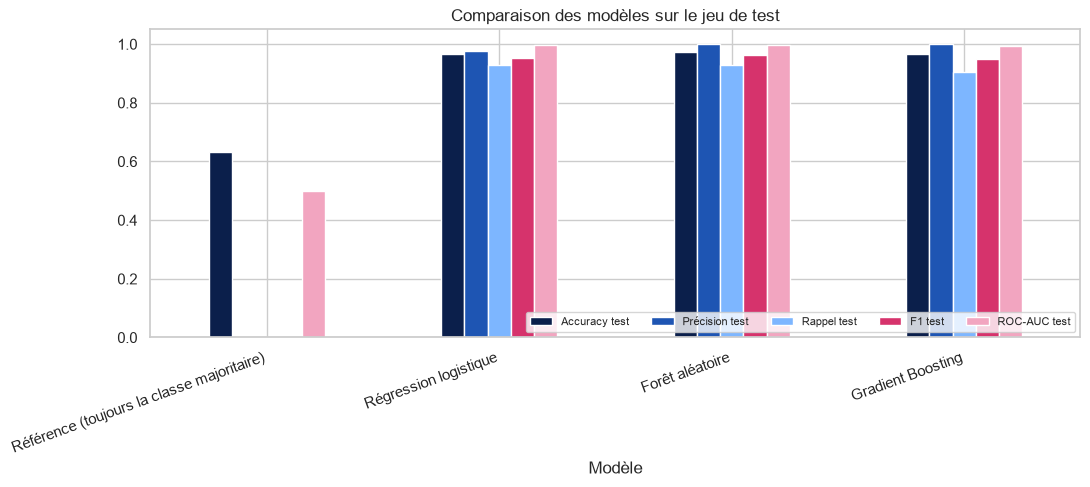

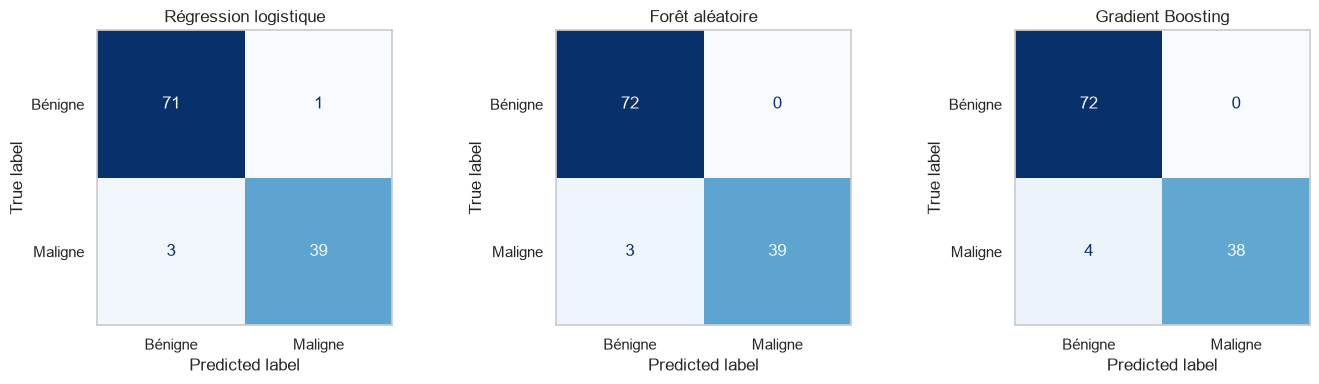

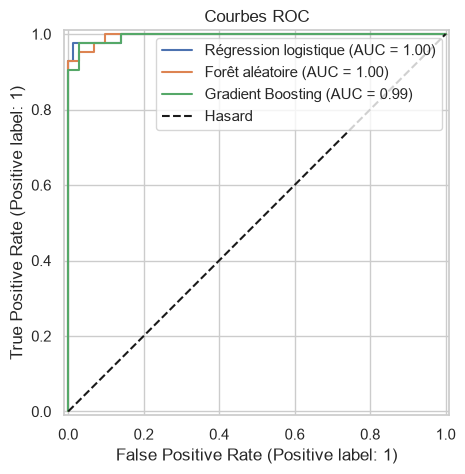

Rapport détaillé du meilleur modèle (Régression logistique) :
              precision    recall  f1-score   support

     Bénigne       0.96      0.99      0.97        72
     Maligne       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [34]:
vrais_modeles = resultats.drop(index="Référence (toujours la classe majoritaire)")
meilleur_nom = vrais_modeles["ROC-AUC validation croisée"].idxmax()
meilleur_modele = entraines[meilleur_nom]
print("Meilleur modèle (d'après le ROC-AUC en validation croisée) :", meilleur_nom)

resultats[["Accuracy test", "Précision test", "Rappel test", "F1 test", "ROC-AUC test"]].plot(
    kind="bar", figsize=(12, 4), color=["#0B1F4B", "#1E55B3", "#7DB6FF", "#D6336C", "#F2A5C0"])
plt.title("Comparaison des modèles sur le jeu de test"); plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right"); plt.legend(loc="lower right", ncol=5, fontsize=8); plt.show()

# Matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, nom in zip(axes, ["Régression logistique", "Forêt aléatoire", "Gradient Boosting"]):
    ConfusionMatrixDisplay.from_estimator(entraines[nom], X_test, y_test, display_labels=NOMS_CLASSES,
                                          ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nom); ax.grid(False)
plt.tight_layout(); plt.show()

# Courbes ROC
plt.figure(figsize=(6, 5))
ax = plt.gca()
for nom in ["Régression logistique", "Forêt aléatoire", "Gradient Boosting"]:
    RocCurveDisplay.from_estimator(entraines[nom], X_test, y_test, ax=ax, name=nom)
plt.plot([0, 1], [0, 1], "k--", label="Hasard"); plt.title("Courbes ROC"); plt.legend(); plt.show()

print(f"Rapport détaillé du meilleur modèle ({meilleur_nom}) :")
print(classification_report(y_test, meilleur_modele.predict(X_test), target_names=NOMS_CLASSES))

### Le seuil de décision
Par défaut, le modèle dit « tumeur maligne » si la probabilité dépasse 0,5. En baissant le seuil, on détecte plus de cas positifs (le **rappel** monte) mais on se trompe plus souvent quand on les annonce (la **précision** baisse).

🩺 **Quelle erreur est la plus grave ici ?** Un **faux négatif** (tumeur maligne annoncée bénigne) est dangereux : la patiente ne serait pas soignée. Un **faux positif** (tumeur bénigne annoncée maligne) provoque des examens supplémentaires, mais est moins grave. On privilégie donc un **rappel élevé** sur la classe « maligne ».

In [35]:
proba = meilleur_modele.predict_proba(X_test)[:, 1]
lignes = []
for seuil in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= seuil).astype(int)
    lignes.append({"Seuil": seuil,
                   "Annoncés « tumeur maligne »": int(pred.sum()),
                   "Précision": precision_score(y_test, pred, zero_division=0),
                   "Rappel": recall_score(y_test, pred, zero_division=0),
                   "F1": f1_score(y_test, pred, zero_division=0)})
pd.DataFrame(lignes).set_index("Seuil").style.format({"Précision": "{:.2f}", "Rappel": "{:.2f}", "F1": "{:.2f}"})

,Annoncés « tumeur maligne »,Précision,Rappel,F1
Seuil,,,,
0.200000,45,0.91,0.98,0.94
0.300000,42,0.98,0.98,0.98
0.400000,41,0.98,0.95,0.96
0.500000,40,0.97,0.93,0.95
0.600000,38,1.00,0.90,0.95
0.700000,38,1.00,0.90,0.95


## 9. Pour aller plus loin
### Quelles variables comptent le plus ?
L'**importance par permutation** mesure de combien le score baisse quand on mélange une variable au hasard : plus la baisse est grande, plus le modèle comptait sur elle.

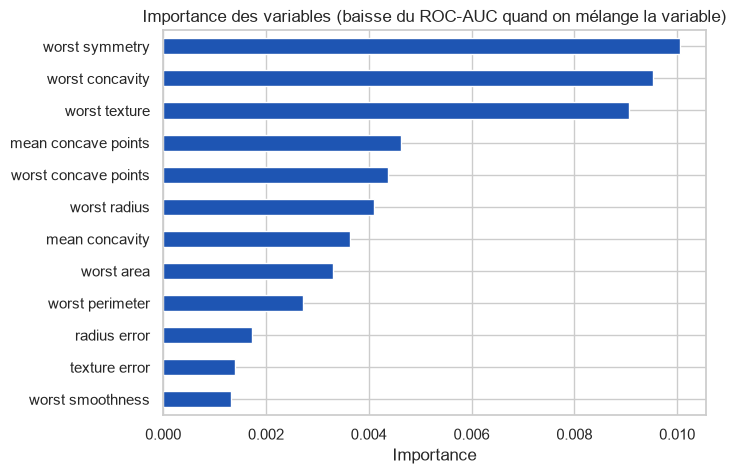

In [36]:
imp = permutation_importance(meilleur_modele, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1)
importances = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
importances.head(12)[::-1].plot(kind="barh", color="#1E55B3")
plt.title("Importance des variables (baisse du ROC-AUC quand on mélange la variable)")
plt.xlabel("Importance"); plt.show()

### Régler un modèle (optionnel)
Chaque modèle a des **hyperparamètres** (ses « boutons de réglage »). On peut chercher automatiquement les meilleurs avec `GridSearchCV`.

In [37]:
# ⏱️ Optionnel : ~1-2 minutes. On teste quelques réglages de la forêt aléatoire.
grille = {
    "model__max_depth": [None, 8, 16],
    "model__min_samples_leaf": [1, 3, 6],
}
recherche = GridSearchCV(faire_modele(RandomForestClassifier(n_estimators=200, class_weight=POIDS, random_state=RANDOM_STATE, n_jobs=-1)),
                         grille, cv=3, scoring="roc_auc")
recherche.fit(X_train, y_train)
print("Meilleurs réglages :", {k.split("__")[-1]: v for k, v in recherche.best_params_.items()})
proba_rf = recherche.predict_proba(X_test)[:, 1]
print(f"ROC-AUC test avant réglage : {resultats.loc['Forêt aléatoire', 'ROC-AUC test']:.3f} → après réglage : {roc_auc_score(y_test, proba_rf):.3f}")

Meilleurs réglages : {'max_depth': None, 'min_samples_leaf': 1}
ROC-AUC test avant réglage : 0.995 → après réglage : 0.994


## 10. Conclusion et préparation du Demo Day

### Ce que nous avons appris
- Avec de bonnes mesures, les trois modèles obtiennent d'excellents scores : le problème est bien « séparable ».
- **L'accuracy ne suffit pas** : ce qui compte, c'est surtout le **rappel** sur les tumeurs malignes (ne pas en rater).
- En baissant le seuil de décision, on peut monter le rappel, au prix de plus de fausses alertes.

### 🤔 Pour préparer le Demo Day
1. Un modèle à 97 % de bonnes réponses est-il suffisant pour un usage médical ? Que faudrait-il de plus ?
2. Qui devrait prendre la décision finale : le modèle ou le médecin ? Comment présenter l'outil ?
3. Les données viennent d'un seul hôpital américain : le modèle marcherait-il aussi bien sur des patientes sénégalaises ?

In [40]:
import joblib

# ✏️ À TOI (5/5) : sauvegarde le modèle, puis recharge-le
# Indice : joblib.dump(objet_à_sauvegarder, "nom_du_fichier.joblib") et joblib.load("nom_du_fichier.joblib")
joblib.dump(meilleur_modele, "modele_cancer_sein.joblib")
print("Modèle sauvegardé dans modele_cancer_sein.joblib : il pourra être rechargé dans l'application (jeudi).")

# Exemple d'utilisation : on prend une ligne du jeu de test et on modifie quelques valeurs
exemple = X_test.iloc[[0]].copy()
# On garde les valeurs d'un vrai cas du jeu de test (30 mesures)
modele_recharge = ...
print("Cas testé :")
display(exemple.T)
modele_recharge = joblib.load("modele_cancer_sein.joblib")
print(f"Probabilité de « tumeur maligne » : {p:.0%}")

Modèle sauvegardé dans modele_cancer_sein.joblib : il pourra être rechargé dans l'application (jeudi).
Cas testé :


,120
mean radius,11.410
mean texture,10.820
mean perimeter,73.340
mean area,403.300
mean smoothness,0.094
mean compactness,0.067
mean concavity,0.035
mean concave points,0.026
mean symmetry,0.167
mean fractal dimension,0.061


Probabilité de « tumeur maligne » : 3730%


<details><summary>💡 Je bloque : voir la solution (5/5)</summary>

```python
joblib.dump(meilleur_modele, "modele_cancer_sein.joblib")
modele_recharge = joblib.load("modele_cancer_sein.joblib")
```
</details>

In [43]:
pip install joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\DELL\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [46]:
import joblib
modele = joblib.load("modele_cancer_sein.joblib")
print(modele)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['mean radius',
                                                   'mean texture',
                                                   'mean perimeter',
                                                   'mean area',
                                                   'mean smoothness',
                                                   'mean compactness',
                                                   'mean concavity',
                                                   'mean concave points',
                       

In [48]:
  import pandas as pd
  df = pd.read_csv("Breast_Cancer.csv", encoding="latin-1")

In [50]:
!streamlit run modele_cancer_sein.joblib.py

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: modele_cancer_sein.joblib.py


### Pour l'application de jeudi
Le fichier `.joblib` contient tout le pipeline (préparation + modèle). Dans l'application, il suffira de :
```python
modele = joblib.load("nom_du_fichier.joblib")
modele.predict(nouvelles_donnees)   # un DataFrame avec les mêmes colonnes que X
```
---
*Notebook réalisé pour le UMEF AI Bootcamp (GalsenAI Ambassador Program). Les explications sont volontairement simples : n'hésite pas à poser des questions aux mentors !*